Upload your Sales Prediction CSV file


Saving CodeAlpha_Sales_Prediction_Dataset.csv to CodeAlpha_Sales_Prediction_Dataset.csv

First 5 rows:


,TV,Radio,Newspaper,Sales
0,232.2,38.9,34.7,22.68
1,131.7,48.6,105.6,17.89
2,257.6,25.0,89.8,19.97
3,209.2,7.2,12.7,10.09
4,28.3,0.7,114.7,2.80



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Features:
      TV  Radio  Newspaper
0  232.2   38.9       34.7
1  131.7   48.6      105.6
2  257.6   25.0       89.8
3  209.2    7.2       12.7
4   28.3    0.7      114.7

Target:
0    22.68
1    17.89
2    19.97
3    10.09
4     2.80
Name: Sales, dtype: float64


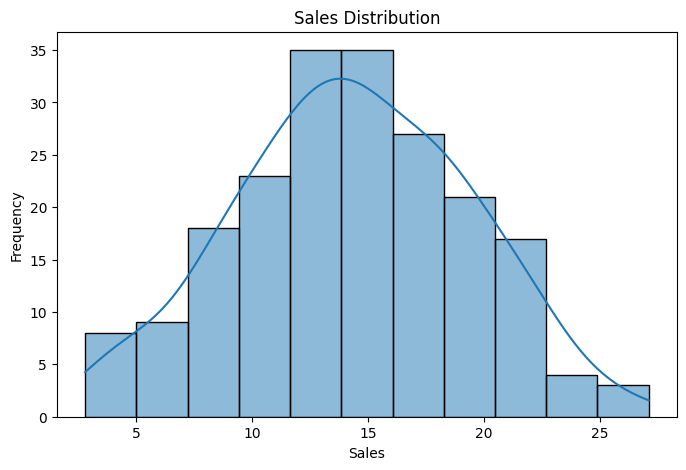

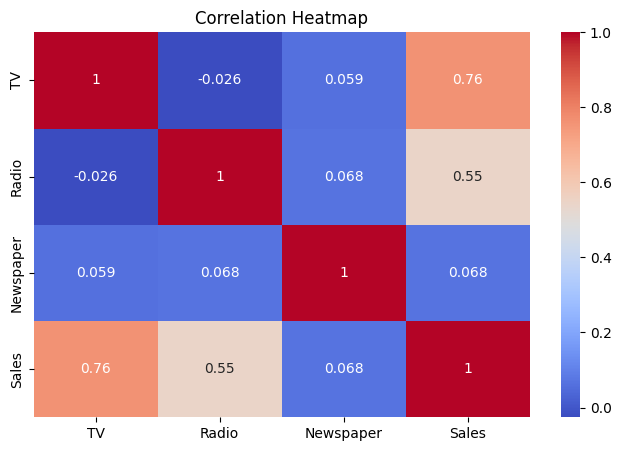

Training data: (160, 3)
Testing data: (40, 3)

Model training completed!

MODEL PERFORMANCE
-------------------------
Mean Absolute Error: 1.2228309534639605
Mean Squared Error: 2.2098120178522387
Root Mean Squared Error: 1.486543648149034
R2 Score: 0.9101568760446703

Actual vs Predicted Sales:


,Actual Sales,Predicted Sales
0,19.03,20.196320
1,15.77,13.121964
2,15.17,13.971501
3,17.76,17.381753
4,9.01,10.186786
5,19.05,17.638879
6,10.04,8.697003
7,14.92,14.204888
8,6.37,6.229986
9,22.58,22.191724


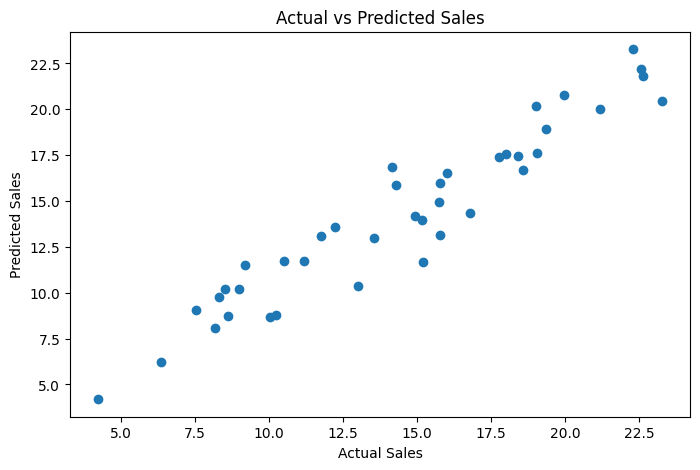


Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


print("Upload your Sales Prediction CSV file")
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())


df.columns = df.columns.str.strip()

target_candidates = ["sales", "sale", "total_sales"]

target = None

for col in df.columns:
    if col.lower() in target_candidates:
        target = col
        break

if target is None:
    raise ValueError(
        "Sales column not found. Please check your CSV column names."
    )

df = df.dropna(subset=[target])

X = df.drop(columns=[target])
y = pd.to_numeric(df[target], errors="coerce")

valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

X = pd.get_dummies(X, drop_first=True)
X = X.fillna(X.median())

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())


plt.figure(figsize=(8, 5))
sns.histplot(y, kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel training completed!")

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("-------------------------")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

print("\nActual vs Predicted Sales:")
display(results.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

import joblib

joblib.dump(model, "sales_prediction_model.pkl")

print("\nModel saved successfully!")

files.download("sales_prediction_model.pkl")